In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.svm import SVC 
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split,GridSearchCV
from pandas.core.dtypes.common import is_numeric_dtype
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [2]:
df = pd.read_csv(r"E:\Codeveda Datasets\churn-bigml-20.csv")

In [3]:
df.shape

(667, 20)

In [4]:
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,415,No,No,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,415,No,No,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,415,No,No,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,510,No,No,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


In [5]:
df.tail()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
662,WI,114,415,No,Yes,26,137.1,88,23.31,155.7,125,13.23,247.6,94,11.14,11.5,7,3.11,2,False
663,AL,106,408,No,Yes,29,83.6,131,14.21,203.9,131,17.33,229.5,73,10.33,8.1,3,2.19,1,False
664,VT,60,415,No,No,0,193.9,118,32.96,85.0,110,7.23,210.1,134,9.45,13.2,8,3.56,3,False
665,WV,159,415,No,No,0,169.8,114,28.87,197.7,105,16.80,193.7,82,8.72,11.6,4,3.13,1,False
666,CT,184,510,Yes,No,0,213.8,105,36.35,159.6,84,13.57,139.2,137,6.26,5.0,10,1.35,2,False


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    object 
 1   Account length          667 non-null    int64  
 2   Area code               667 non-null    int64  
 3   International plan      667 non-null    object 
 4   Voice mail plan         667 non-null    object 
 5   Number vmail messages   667 non-null    int64  
 6   Total day minutes       667 non-null    float64
 7   Total day calls         667 non-null    int64  
 8   Total day charge        667 non-null    float64
 9   Total eve minutes       667 non-null    float64
 10  Total eve calls         667 non-null    int64  
 11  Total eve charge        667 non-null    float64
 12  Total night minutes     667 non-null    float64
 13  Total night calls       667 non-null    int64  
 14  Total night charge      667 non-null    fl

In [7]:
df.isnull().any()

State                     False
Account length            False
Area code                 False
International plan        False
Voice mail plan           False
Number vmail messages     False
Total day minutes         False
Total day calls           False
Total day charge          False
Total eve minutes         False
Total eve calls           False
Total eve charge          False
Total night minutes       False
Total night calls         False
Total night charge        False
Total intl minutes        False
Total intl calls          False
Total intl charge         False
Customer service calls    False
Churn                     False
dtype: bool

In [8]:
df.duplicated().any()

np.False_

In [9]:
df.describe(include = "all")

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
count,667,667.000000,667.000000,667,667,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667
unique,51,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,AZ,NaN,NaN,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
freq,19,NaN,NaN,614,478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,572
mean,NaN,102.841079,436.157421,NaN,NaN,8.407796,180.948126,100.937031,30.761769,203.355322,100.476762,17.285262,199.685307,100.113943,8.985907,10.238381,4.527736,2.764948,1.563718,NaN
std,NaN,40.819480,41.783305,NaN,NaN,13.994480,55.508628,20.396790,9.436463,49.719268,18.948262,4.226160,49.759931,20.172505,2.239429,2.807850,2.482442,0.758167,1.333357,NaN
min,NaN,1.000000,408.000000,NaN,NaN,0.000000,25.900000,30.000000,4.400000,48.100000,37.000000,4.090000,23.200000,42.000000,1.040000,0.000000,0.000000,0.000000,0.000000,NaN
25%,NaN,76.000000,408.000000,NaN,NaN,0.000000,146.250000,87.500000,24.860000,171.050000,88.000000,14.540000,167.950000,86.000000,7.560000,8.600000,3.000000,2.320000,1.000000,NaN
50%,NaN,102.000000,415.000000,NaN,NaN,0.000000,178.300000,101.000000,30.310000,203.700000,101.000000,17.310000,201.600000,100.000000,9.070000,10.500000,4.000000,2.840000,1.000000,NaN
75%,NaN,128.000000,415.000000,NaN,NaN,20.000000,220.700000,115.000000,37.520000,236.450000,113.000000,20.095000,231.500000,113.500000,10.420000,12.050000,6.000000,3.255000,2.000000,NaN


(array([ 12.,  16.,  28.,  39.,  83., 105.,  95., 101.,  71.,  43.,  40.,
         14.,  13.,   5.,   2.]),
 array([  1. ,  16.4,  31.8,  47.2,  62.6,  78. ,  93.4, 108.8, 124.2,
        139.6, 155. , 170.4, 185.8, 201.2, 216.6, 232. ]),
 <BarContainer object of 15 artists>)

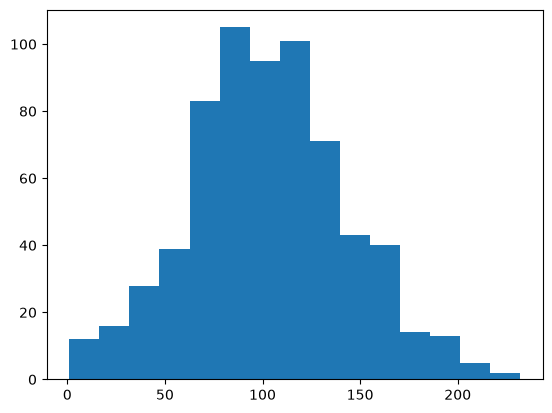

In [10]:
plt.hist(df["Account length"],bins = 15)

(array([169., 337.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0., 161.]),
 array([408. , 414.8, 421.6, 428.4, 435.2, 442. , 448.8, 455.6, 462.4,
        469.2, 476. , 482.8, 489.6, 496.4, 503.2, 510. ]),
 <BarContainer object of 15 artists>)

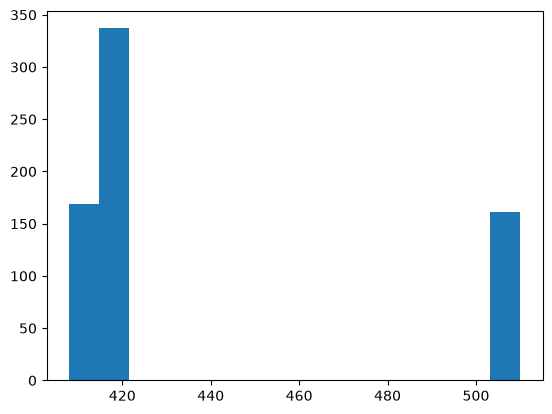

In [11]:
plt.hist(df["Area code"],bins = 15)

(array([478.,   0.,   0.,   3.,   5.,  16.,  20.,  28.,  32.,  27.,  29.,
         14.,   8.,   3.,   4.]),
 array([ 0. ,  3.4,  6.8, 10.2, 13.6, 17. , 20.4, 23.8, 27.2, 30.6, 34. ,
        37.4, 40.8, 44.2, 47.6, 51. ]),
 <BarContainer object of 15 artists>)

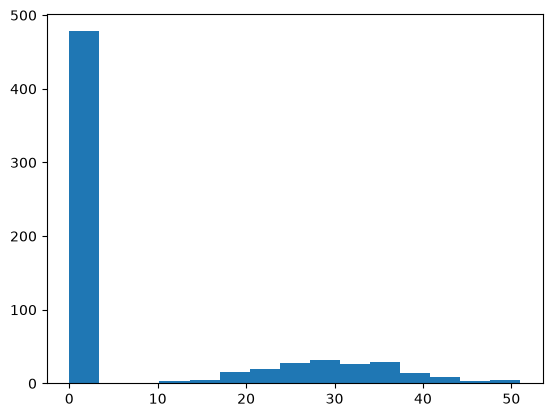

In [12]:
plt.hist(df["Number vmail messages"],bins = 15)

(array([  4.,   8.,  22.,  30.,  47.,  74., 110.,  91.,  79.,  74.,  63.,
         31.,  19.,   8.,   7.]),
 array([ 25.9 ,  46.46,  67.02,  87.58, 108.14, 128.7 , 149.26, 169.82,
        190.38, 210.94, 231.5 , 252.06, 272.62, 293.18, 313.74, 334.3 ]),
 <BarContainer object of 15 artists>)

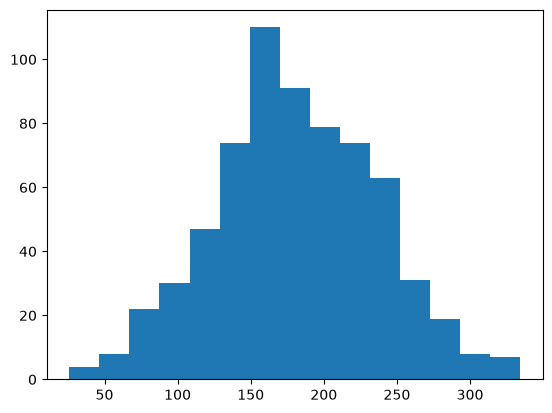

In [13]:
plt.hist(df["Total day minutes"],bins = 15)

(array([  2.,   1.,  10.,  11.,  43.,  62.,  98., 115., 110.,  88.,  70.,
         30.,  22.,   3.,   2.]),
 array([ 30.,  39.,  48.,  57.,  66.,  75.,  84.,  93., 102., 111., 120.,
        129., 138., 147., 156., 165.]),
 <BarContainer object of 15 artists>)

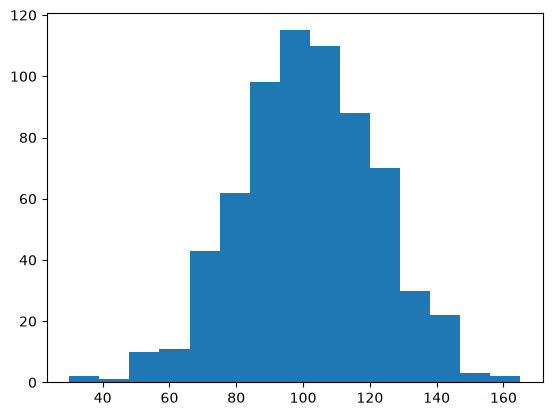

In [14]:
plt.hist(df["Total day calls"],bins = 15)

(array([  5.,   9.,   9.,  26.,  47.,  80., 107., 122.,  94.,  74.,  54.,
         22.,  11.,   4.,   3.]),
 array([ 48.1       ,  69.01333333,  89.92666667, 110.84      ,
        131.75333333, 152.66666667, 173.58      , 194.49333333,
        215.40666667, 236.32      , 257.23333333, 278.14666667,
        299.06      , 319.97333333, 340.88666667, 361.8       ]),
 <BarContainer object of 15 artists>)

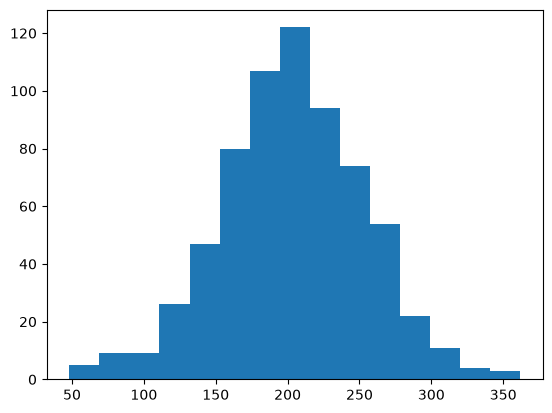

In [15]:
plt.hist(df["Total eve minutes"],bins = 15)

(array([  1.,   6.,  10.,  27.,  49.,  97., 118., 116., 100.,  74.,  44.,
         14.,   7.,   2.,   2.]),
 array([ 37.        ,  45.73333333,  54.46666667,  63.2       ,
         71.93333333,  80.66666667,  89.4       ,  98.13333333,
        106.86666667, 115.6       , 124.33333333, 133.06666667,
        141.8       , 150.53333333, 159.26666667, 168.        ]),
 <BarContainer object of 15 artists>)

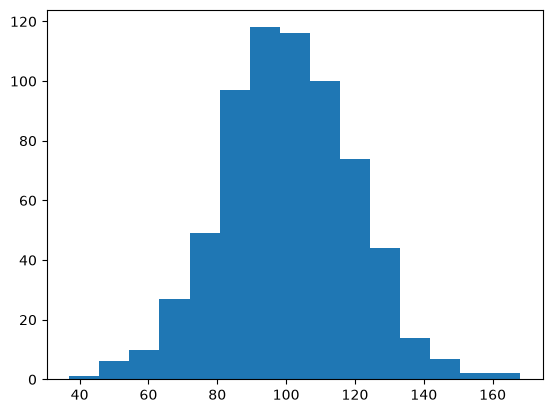

In [16]:
plt.hist(df["Total eve calls"],bins = 15)

(array([  5.,   9.,   9.,  26.,  47.,  80., 108., 121.,  94.,  74.,  54.,
         22.,  11.,   4.,   3.]),
 array([ 4.09      ,  5.86733333,  7.64466667,  9.422     , 11.19933333,
        12.97666667, 14.754     , 16.53133333, 18.30866667, 20.086     ,
        21.86333333, 23.64066667, 25.418     , 27.19533333, 28.97266667,
        30.75      ]),
 <BarContainer object of 15 artists>)

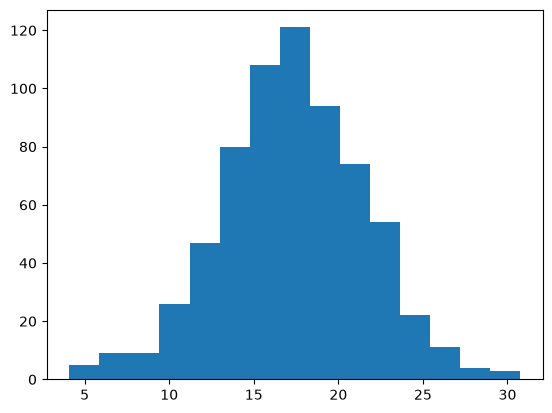

In [17]:
plt.hist(df["Total eve charge"],bins = 15)

(array([  1.,   3.,  11.,  11.,  46.,  72., 100., 123., 124.,  87.,  49.,
         23.,  12.,   2.,   3.]),
 array([ 23.2       ,  46.16666667,  69.13333333,  92.1       ,
        115.06666667, 138.03333333, 161.        , 183.96666667,
        206.93333333, 229.9       , 252.86666667, 275.83333333,
        298.8       , 321.76666667, 344.73333333, 367.7       ]),
 <BarContainer object of 15 artists>)

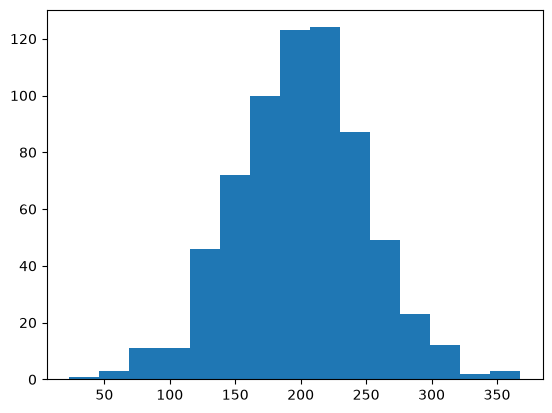

In [18]:
plt.hist(df["Total night minutes"],bins = 15)

(array([  1.,  13.,  22.,  57.,  79., 115., 109.,  94.,  73.,  55.,  35.,
          9.,   4.,   0.,   1.]),
 array([ 42.        ,  50.86666667,  59.73333333,  68.6       ,
         77.46666667,  86.33333333,  95.2       , 104.06666667,
        112.93333333, 121.8       , 130.66666667, 139.53333333,
        148.4       , 157.26666667, 166.13333333, 175.        ]),
 <BarContainer object of 15 artists>)

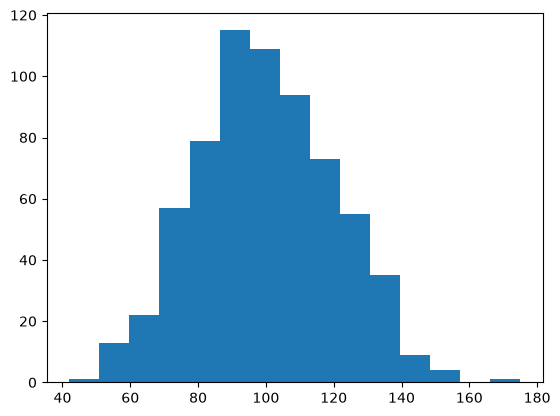

In [19]:
plt.hist(df["Total night calls"],bins = 15)

(array([  1.,   3.,  11.,  11.,  45.,  73., 100., 123., 124.,  87.,  49.,
         23.,  12.,   2.,   3.]),
 array([ 1.04 ,  2.074,  3.108,  4.142,  5.176,  6.21 ,  7.244,  8.278,
         9.312, 10.346, 11.38 , 12.414, 13.448, 14.482, 15.516, 16.55 ]),
 <BarContainer object of 15 artists>)

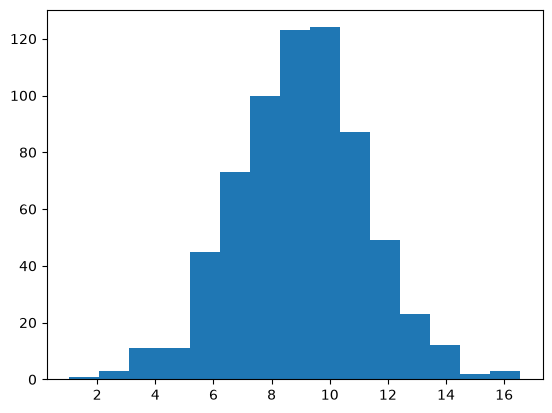

In [20]:
plt.hist(df["Total night charge"],bins = 15)

(array([  3.,   3.,   2.,  13.,  33.,  45.,  67.,  95., 131., 118.,  90.,
         34.,  19.,  10.,   4.]),
 array([ 0.  ,  1.22,  2.44,  3.66,  4.88,  6.1 ,  7.32,  8.54,  9.76,
        10.98, 12.2 , 13.42, 14.64, 15.86, 17.08, 18.3 ]),
 <BarContainer object of 15 artists>)

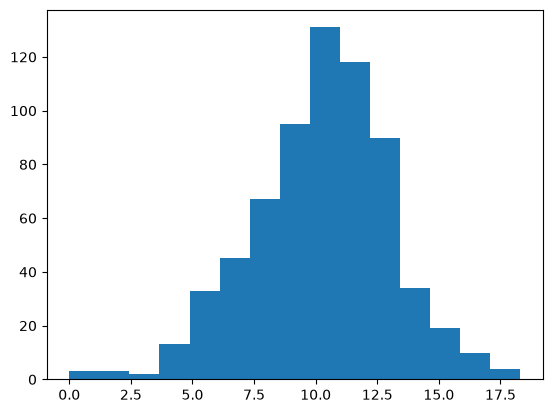

In [21]:
plt.hist(df["Total intl minutes"],bins = 15)

(array([ 38., 101., 124., 116.,  96., 115.,  26.,  26.,  13.,   3.,   4.,
          1.,   3.,   0.,   1.]),
 array([ 0. ,  1.2,  2.4,  3.6,  4.8,  6. ,  7.2,  8.4,  9.6, 10.8, 12. ,
        13.2, 14.4, 15.6, 16.8, 18. ]),
 <BarContainer object of 15 artists>)

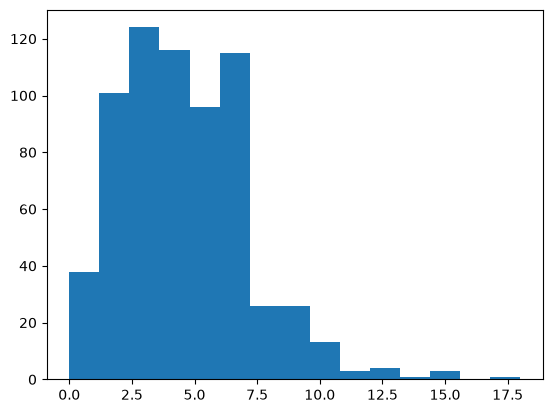

In [22]:
plt.hist(df["Total intl calls"],bins = 15)

(array([  3.,   3.,   2.,  13.,  33.,  45.,  67.,  95., 131., 125.,  83.,
         34.,  19.,  10.,   4.]),
 array([0.        , 0.32933333, 0.65866667, 0.988     , 1.31733333,
        1.64666667, 1.976     , 2.30533333, 2.63466667, 2.964     ,
        3.29333333, 3.62266667, 3.952     , 4.28133333, 4.61066667,
        4.94      ]),
 <BarContainer object of 15 artists>)

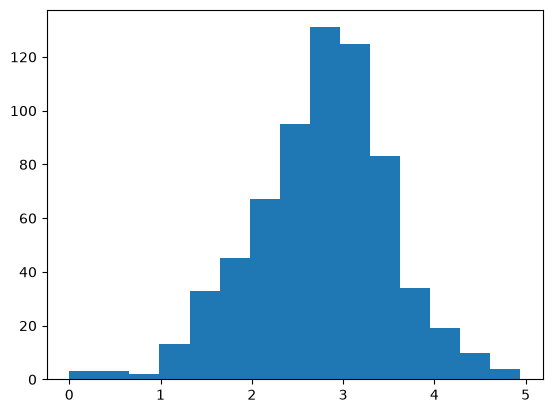

In [23]:
plt.hist(df["Total intl charge"],bins = 15)

(array([142., 236.,   0., 151.,   0.,  81.,   0.,  33.,   0.,  17.,   0.,
          5.,   0.,   1.,   1.]),
 array([0.        , 0.53333333, 1.06666667, 1.6       , 2.13333333,
        2.66666667, 3.2       , 3.73333333, 4.26666667, 4.8       ,
        5.33333333, 5.86666667, 6.4       , 6.93333333, 7.46666667,
        8.        ]),
 <BarContainer object of 15 artists>)

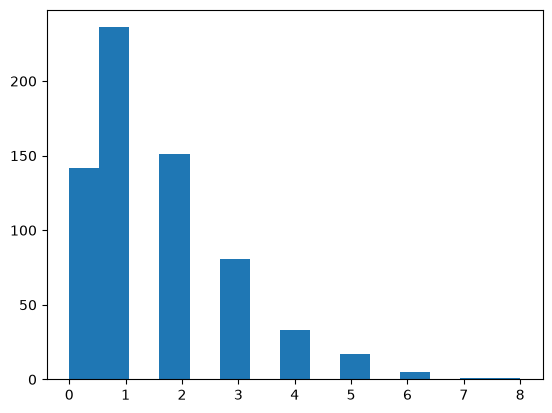

In [24]:
plt.hist(df["Customer service calls"],bins = 15)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\1421313601.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Account length"])


<Axes: xlabel='Account length', ylabel='Density'>

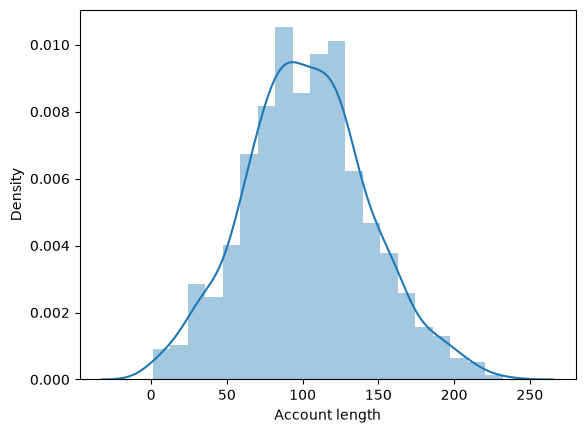

In [25]:
sns.distplot(df["Account length"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\952462465.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Area code"])


<Axes: xlabel='Area code', ylabel='Density'>

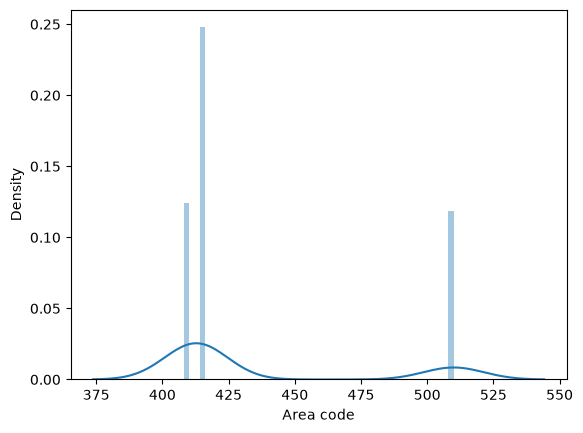

In [26]:
sns.distplot(df["Area code"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\3742156619.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Number vmail messages"])


<Axes: xlabel='Number vmail messages', ylabel='Density'>

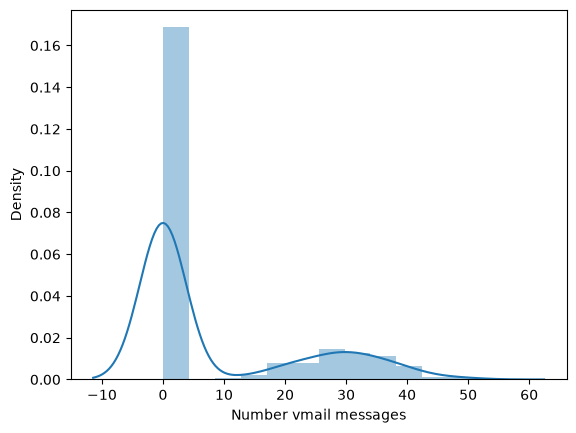

In [27]:
sns.distplot(df["Number vmail messages"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\981084958.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Total day minutes"])


<Axes: xlabel='Total day minutes', ylabel='Density'>

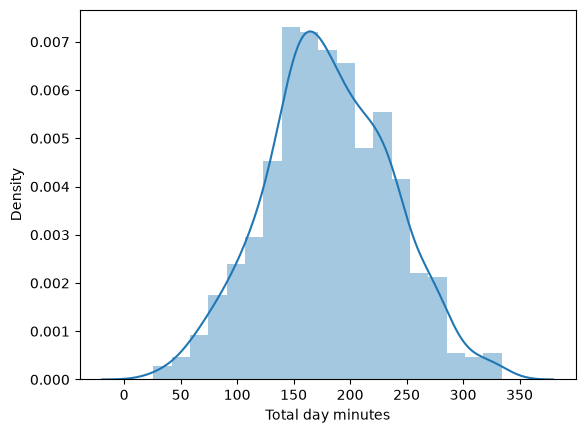

In [28]:
sns.distplot(df["Total day minutes"])

In [29]:
df.columns

Index(['State', 'Account length', 'Area code', 'International plan',
       'Voice mail plan', 'Number vmail messages', 'Total day minutes',
       'Total day calls', 'Total day charge', 'Total eve minutes',
       'Total eve calls', 'Total eve charge', 'Total night minutes',
       'Total night calls', 'Total night charge', 'Total intl minutes',
       'Total intl calls', 'Total intl charge', 'Customer service calls',
       'Churn'],
      dtype='object')

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\2230693675.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total day calls'])


<Axes: xlabel='Total day calls', ylabel='Density'>

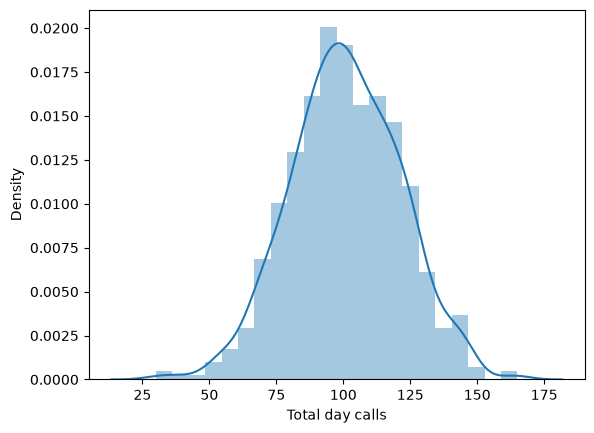

In [30]:
sns.distplot(df['Total day calls'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\3428253055.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total day charge'])


<Axes: xlabel='Total day charge', ylabel='Density'>

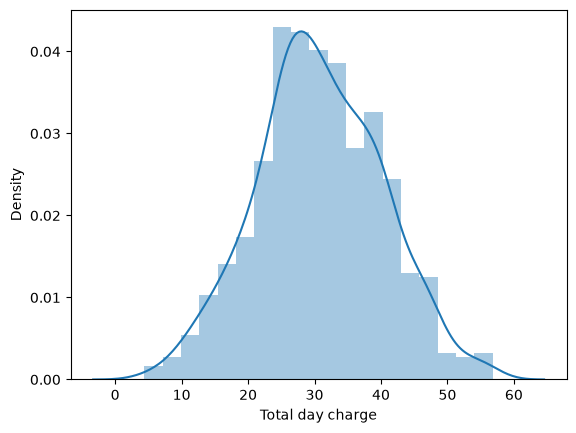

In [31]:
sns.distplot(df['Total day charge'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\1016329958.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total eve minutes'])


<Axes: xlabel='Total eve minutes', ylabel='Density'>

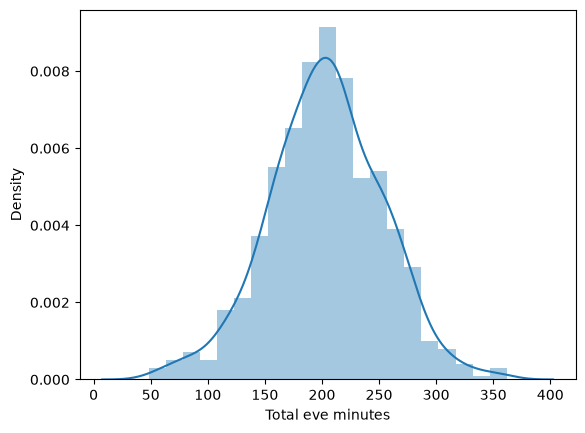

In [32]:
sns.distplot(df['Total eve minutes'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\2832165031.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total eve calls'])


<Axes: xlabel='Total eve calls', ylabel='Density'>

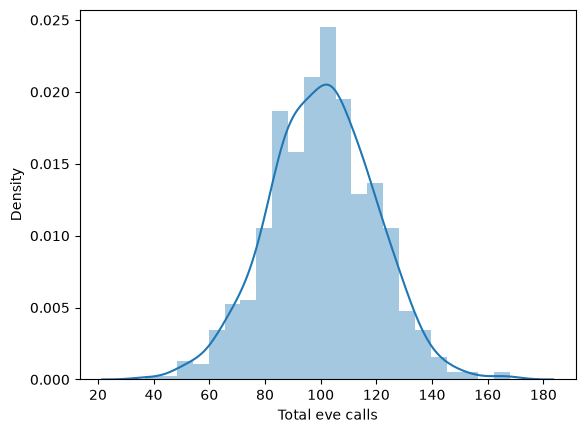

In [33]:
sns.distplot(df['Total eve calls'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\3209565758.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total eve charge'])


<Axes: xlabel='Total eve charge', ylabel='Density'>

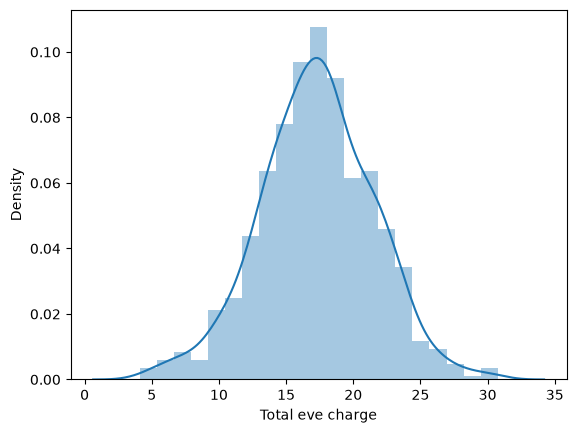

In [34]:
sns.distplot(df['Total eve charge'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\2001629642.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total night minutes'])


<Axes: xlabel='Total night minutes', ylabel='Density'>

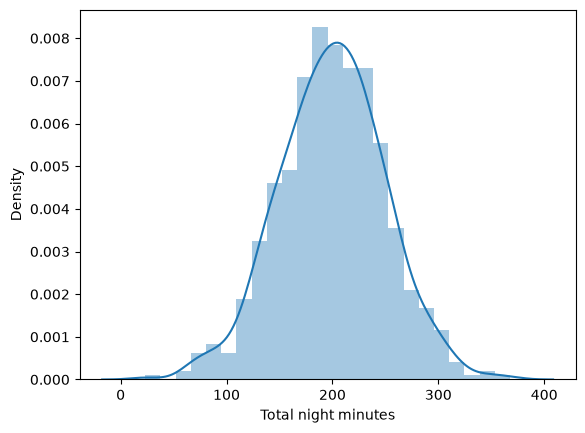

In [35]:
sns.distplot(df['Total night minutes'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\4220438819.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total night calls'])


<Axes: xlabel='Total night calls', ylabel='Density'>

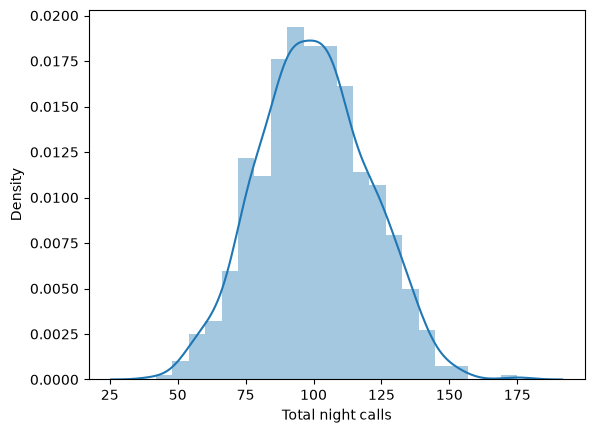

In [36]:
sns.distplot(df['Total night calls'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\1075615655.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total night charge'])


<Axes: xlabel='Total night charge', ylabel='Density'>

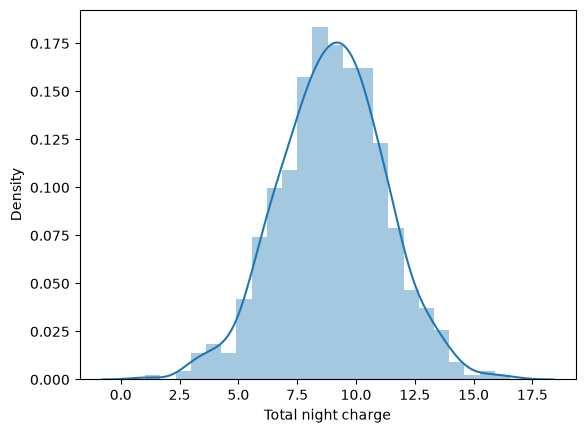

In [37]:
sns.distplot(df['Total night charge'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\3803285122.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total intl minutes'])


<Axes: xlabel='Total intl minutes', ylabel='Density'>

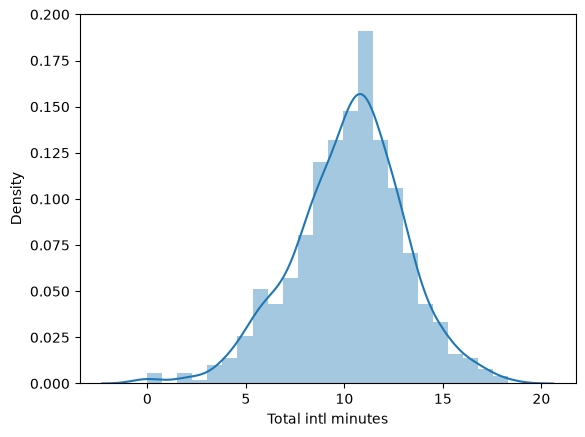

In [38]:
sns.distplot(df['Total intl minutes'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\1185801225.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total intl calls'])


<Axes: xlabel='Total intl calls', ylabel='Density'>

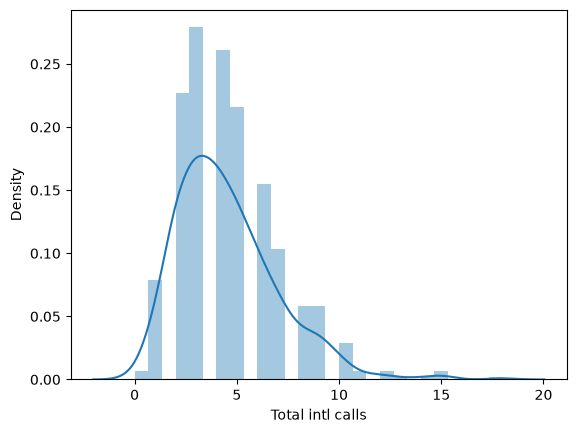

In [39]:
sns.distplot(df['Total intl calls'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\173921831.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Total intl charge'])


<Axes: xlabel='Total intl charge', ylabel='Density'>

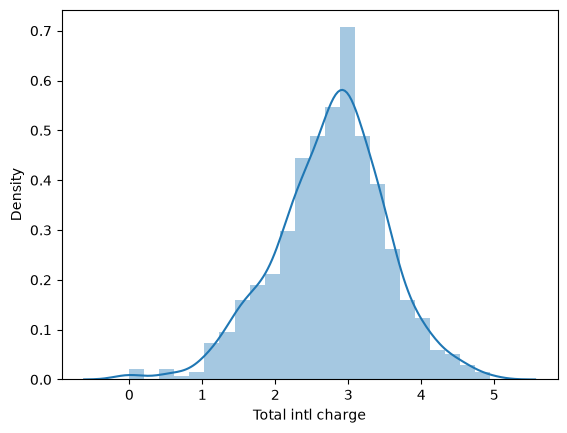

In [40]:
sns.distplot(df['Total intl charge'])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\346688707.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Customer service calls'])


<Axes: xlabel='Customer service calls', ylabel='Density'>

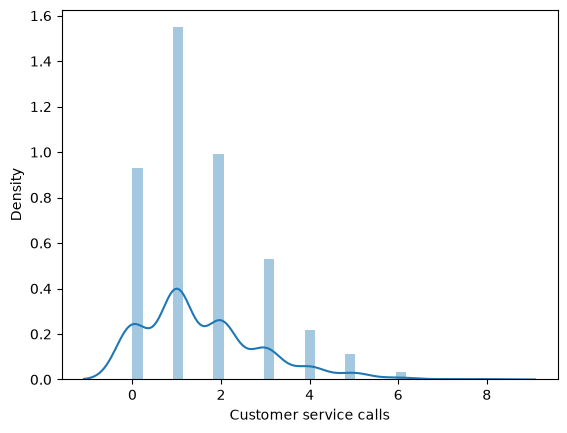

In [41]:
sns.distplot(df['Customer service calls'])

In [42]:
df.columns

Index(['State', 'Account length', 'Area code', 'International plan',
       'Voice mail plan', 'Number vmail messages', 'Total day minutes',
       'Total day calls', 'Total day charge', 'Total eve minutes',
       'Total eve calls', 'Total eve charge', 'Total night minutes',
       'Total night calls', 'Total night charge', 'Total intl minutes',
       'Total intl calls', 'Total intl charge', 'Customer service calls',
       'Churn'],
      dtype='object')

<Axes: ylabel='Account length'>

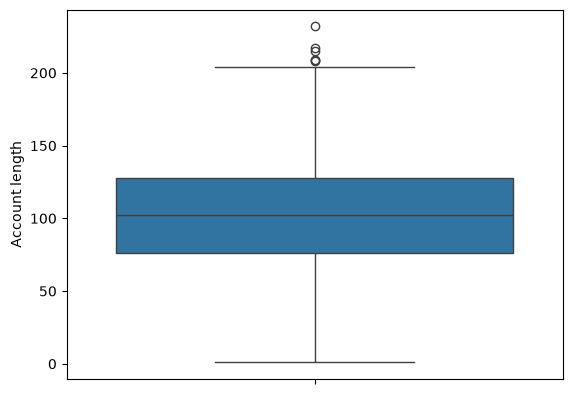

In [43]:
sns.boxplot(df['Account length'])

<Axes: ylabel='Area code'>

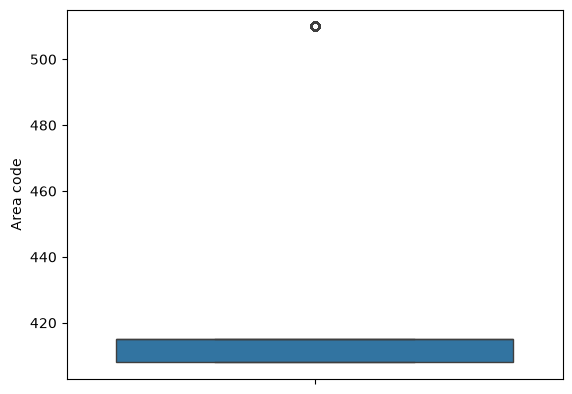

In [44]:
sns.boxplot(df['Area code'])

<Axes: ylabel='Number vmail messages'>

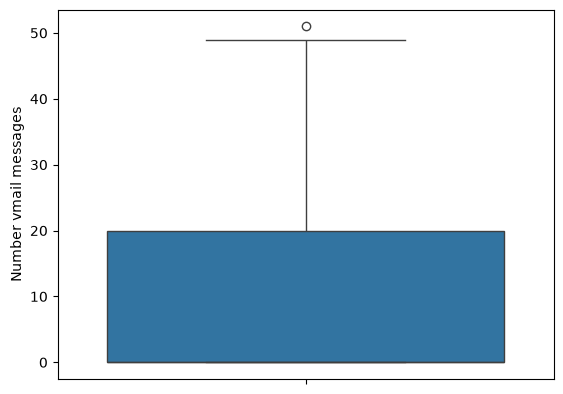

In [45]:
sns.boxplot(df['Number vmail messages'])

<Axes: ylabel='Total day minutes'>

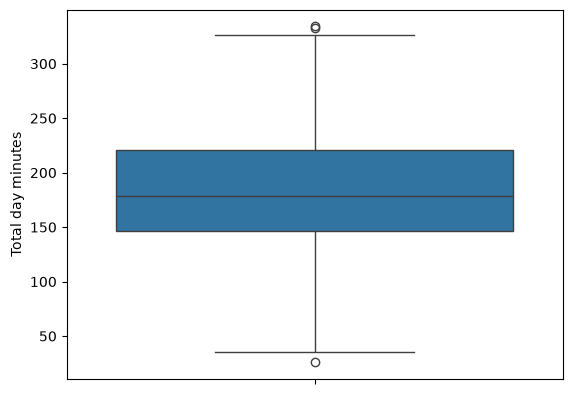

In [46]:
sns.boxplot(df['Total day minutes'])

In [47]:
df.columns

Index(['State', 'Account length', 'Area code', 'International plan',
       'Voice mail plan', 'Number vmail messages', 'Total day minutes',
       'Total day calls', 'Total day charge', 'Total eve minutes',
       'Total eve calls', 'Total eve charge', 'Total night minutes',
       'Total night calls', 'Total night charge', 'Total intl minutes',
       'Total intl calls', 'Total intl charge', 'Customer service calls',
       'Churn'],
      dtype='object')

<Axes: ylabel='Total day calls'>

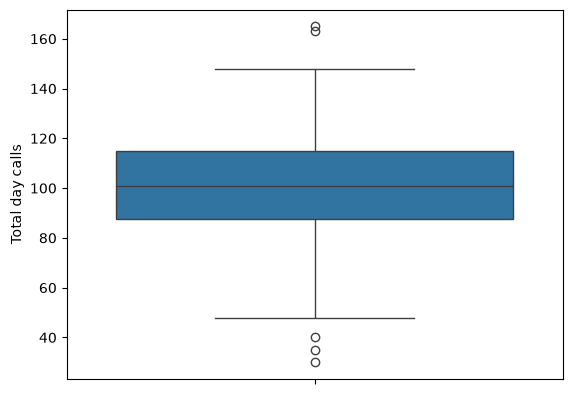

In [48]:
sns.boxplot(df['Total day calls'])

<Axes: ylabel='Total day charge'>

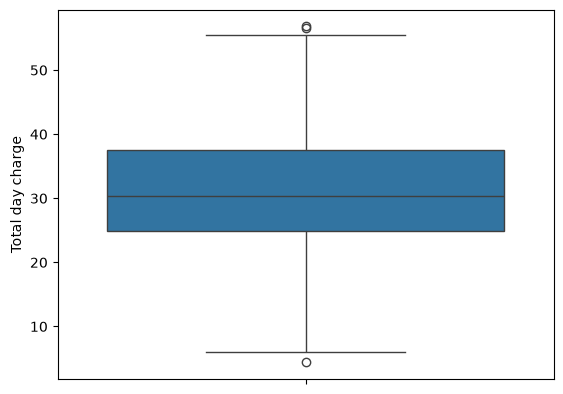

In [49]:
sns.boxplot(df['Total day charge'])

<Axes: ylabel='Total eve minutes'>

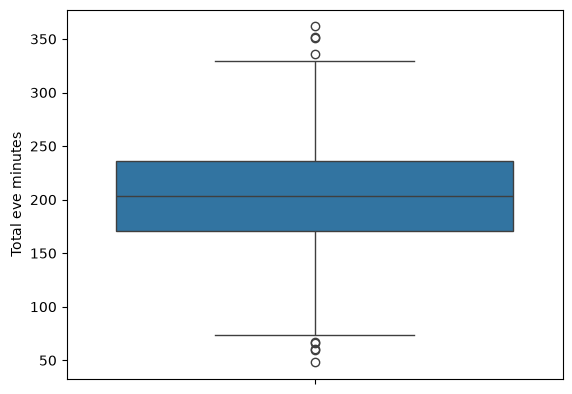

In [50]:
sns.boxplot(df['Total eve minutes'])

<Axes: ylabel='Total eve calls'>

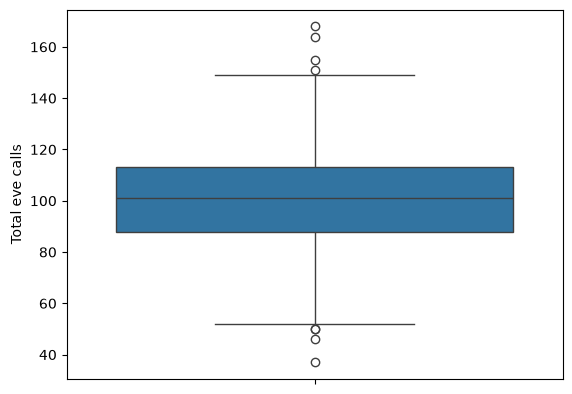

In [51]:
sns.boxplot(df['Total eve calls'])

<Axes: ylabel='Total eve charge'>

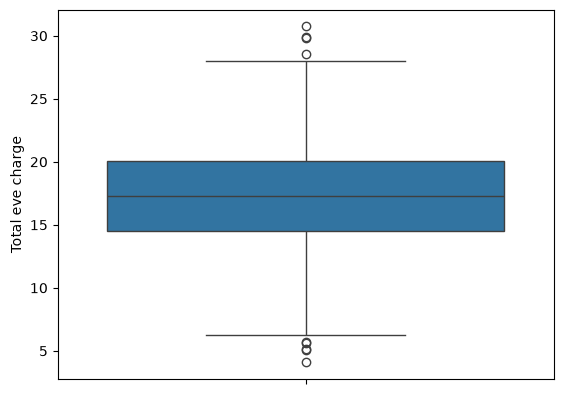

In [52]:
sns.boxplot(df['Total eve charge'])

<Axes: ylabel='Total night minutes'>

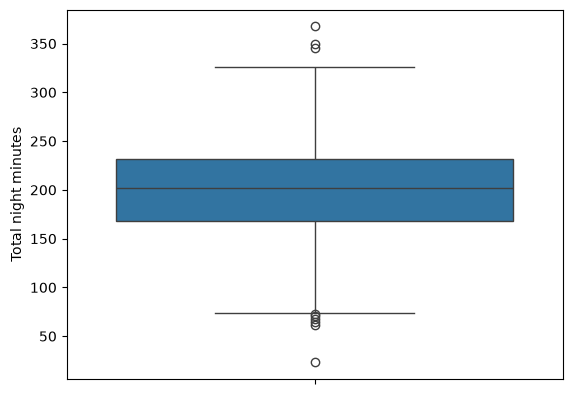

In [53]:
sns.boxplot(df['Total night minutes'])

<Axes: ylabel='Total night calls'>

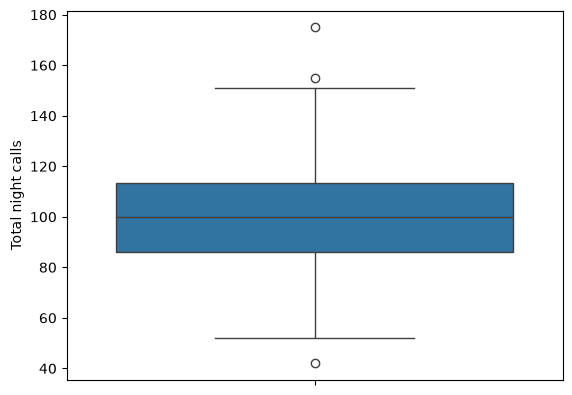

In [54]:
sns.boxplot(df['Total night calls'])

<Axes: ylabel='Total night charge'>

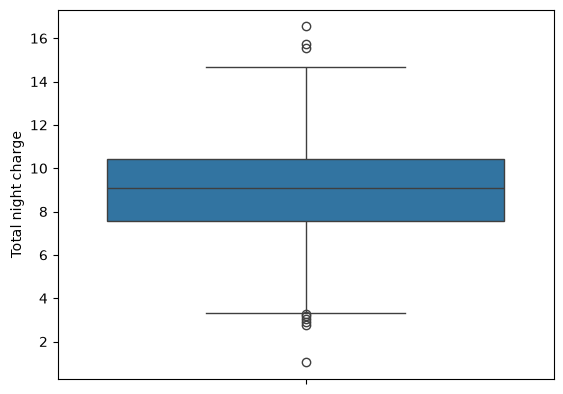

In [55]:
sns.boxplot(df['Total night charge'])

<Axes: ylabel='Total intl minutes'>

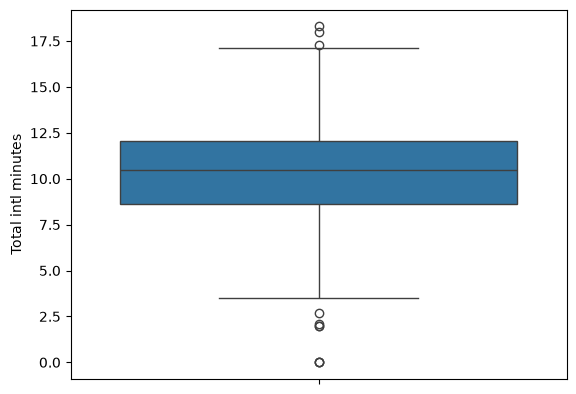

In [56]:
sns.boxplot(df['Total intl minutes'])

<Axes: ylabel='Total intl calls'>

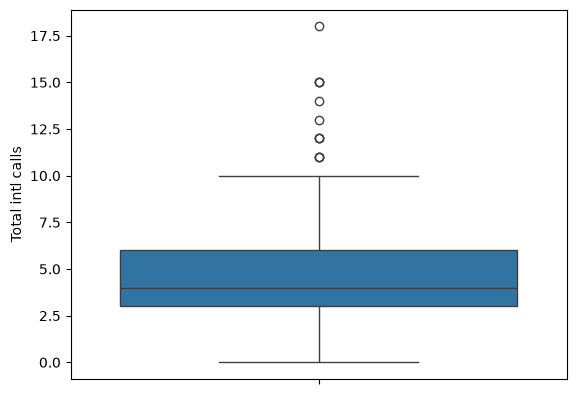

In [57]:
sns.boxplot(df['Total intl calls'])

<Axes: ylabel='Total intl charge'>

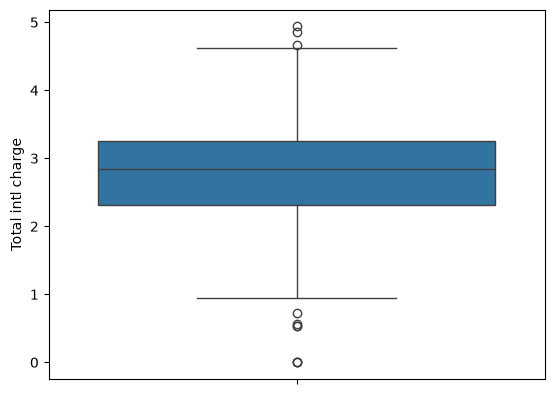

In [58]:
sns.boxplot(df['Total intl charge'])

<Axes: ylabel='Customer service calls'>

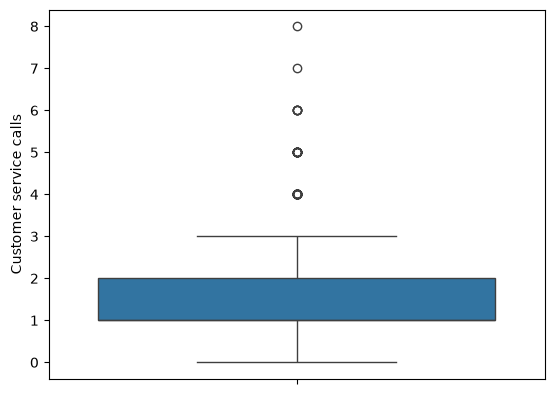

In [59]:
sns.boxplot(df['Customer service calls'])

<Axes: ylabel='count'>

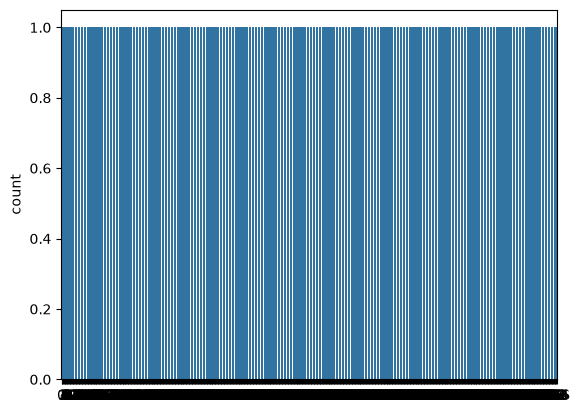

In [60]:
sns.countplot(df['Churn'])

<Axes: ylabel='Churn'>

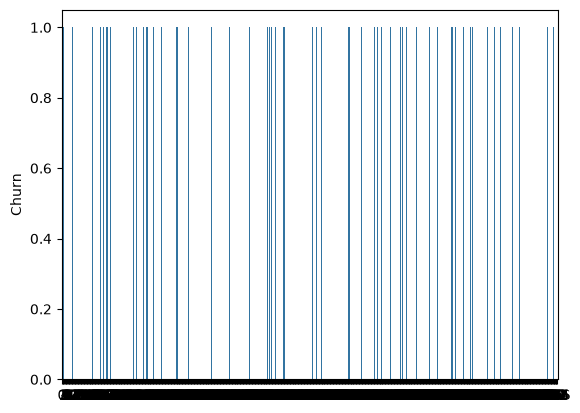

In [61]:
sns.barplot(df['Churn'])

<Axes: ylabel='count'>

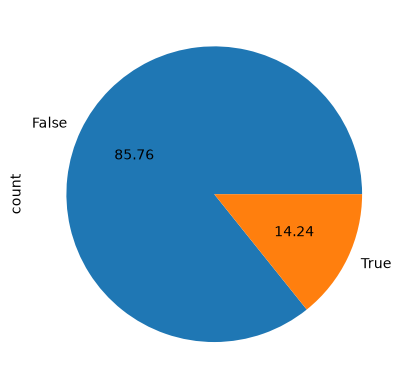

In [62]:
df["Churn"].value_counts().plot(kind='pie',autopct='%.2f')

<Axes: xlabel='Account length', ylabel='Area code'>

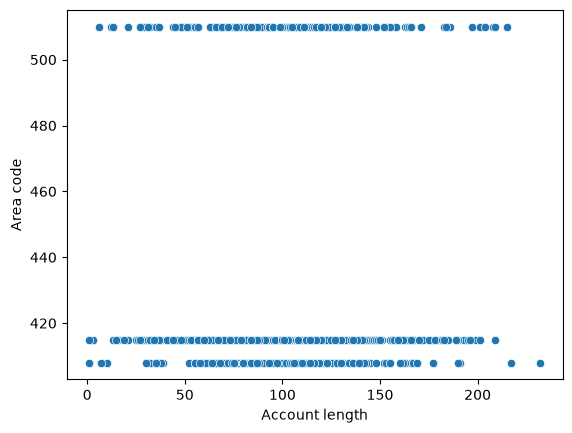

In [63]:
sns.scatterplot(x=df['Account length'],y=df['Area code'])

In [64]:
df.columns

Index(['State', 'Account length', 'Area code', 'International plan',
       'Voice mail plan', 'Number vmail messages', 'Total day minutes',
       'Total day calls', 'Total day charge', 'Total eve minutes',
       'Total eve calls', 'Total eve charge', 'Total night minutes',
       'Total night calls', 'Total night charge', 'Total intl minutes',
       'Total intl calls', 'Total intl charge', 'Customer service calls',
       'Churn'],
      dtype='object')

<Axes: xlabel='Account length', ylabel='Number vmail messages'>

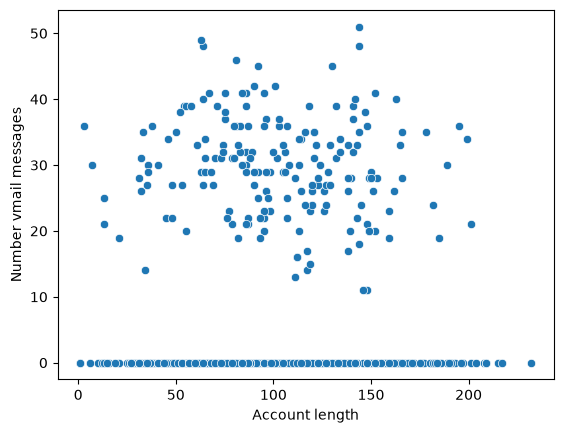

In [65]:
sns.scatterplot(x=df['Account length'],y=df['Number vmail messages'])

<Axes: xlabel='Account length', ylabel='Total day minutes'>

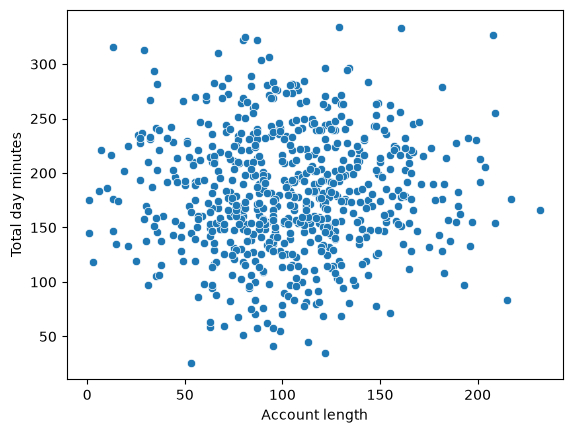

In [66]:
sns.scatterplot(x=df['Account length'],y=df['Total day minutes'])

<Axes: xlabel='Account length', ylabel='Total day calls'>

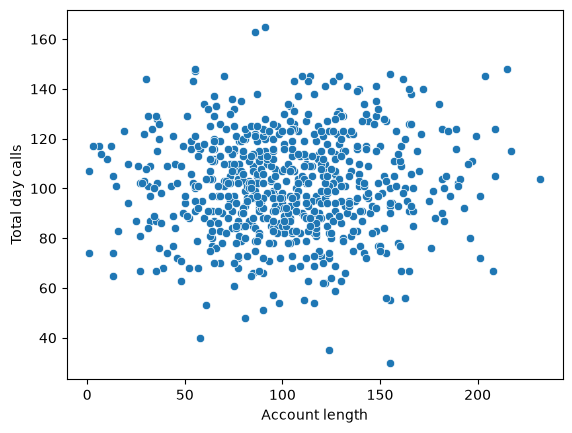

In [67]:
sns.scatterplot(x=df['Account length'],y=df['Total day calls'])

<Axes: xlabel='Account length', ylabel='Total day charge'>

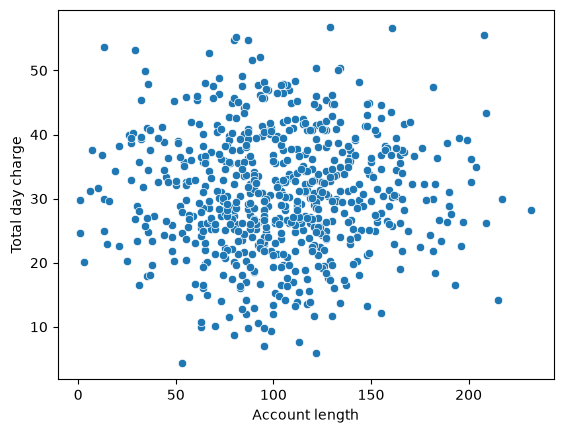

In [68]:
sns.scatterplot(x=df['Account length'],y=df['Total day charge'])

<Axes: xlabel='Account length', ylabel='Total eve minutes'>

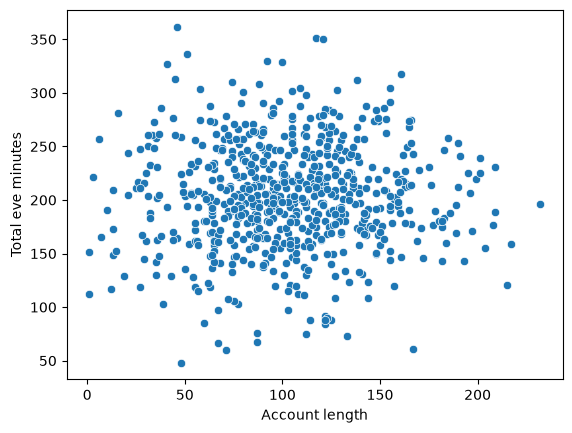

In [69]:
sns.scatterplot(x=df['Account length'],y=df['Total eve minutes'])

<Axes: xlabel='Account length', ylabel='Total eve calls'>

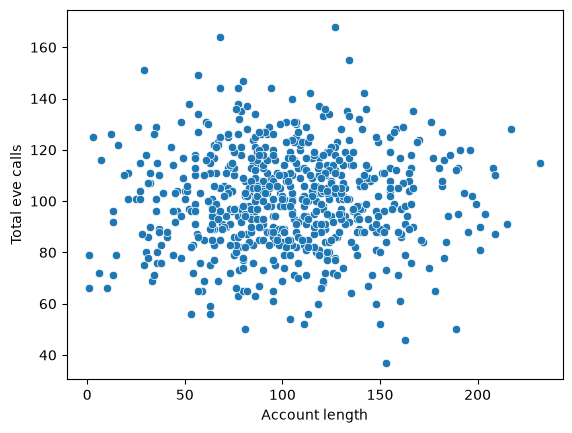

In [70]:
sns.scatterplot(x=df['Account length'],y=df['Total eve calls'])

<Axes: xlabel='Account length', ylabel='Total eve charge'>

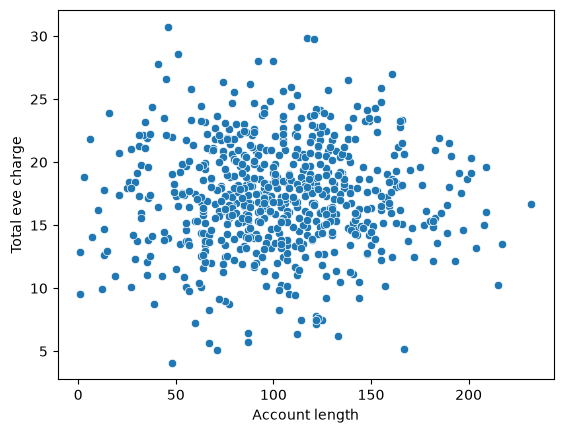

In [71]:
sns.scatterplot(x=df['Account length'],y=df['Total eve charge'])

<Axes: xlabel='Account length', ylabel='Total night minutes'>

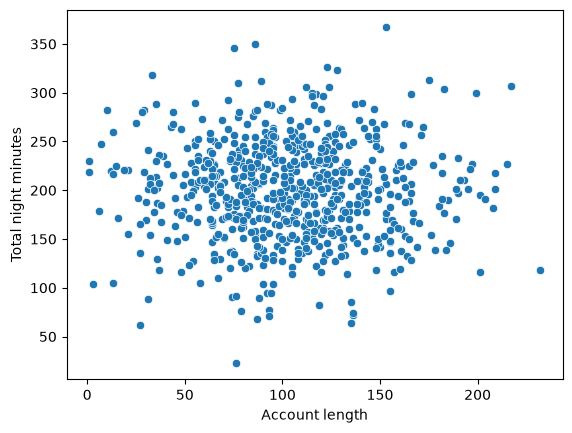

In [72]:
sns.scatterplot(x=df['Account length'],y=df['Total night minutes'])

<Axes: xlabel='Account length', ylabel='Total night calls'>

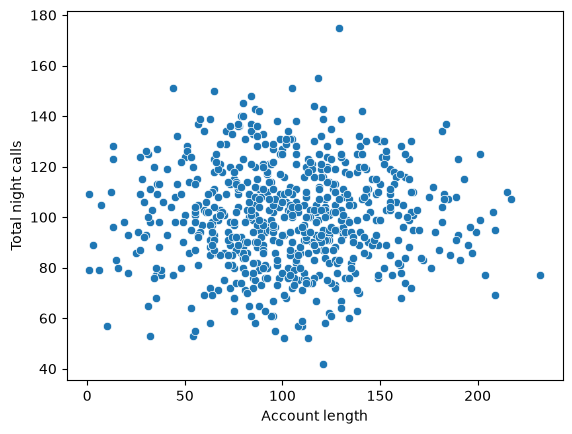

In [73]:
sns.scatterplot(x=df['Account length'],y=df['Total night calls'])

<Axes: xlabel='Account length', ylabel='Total night charge'>

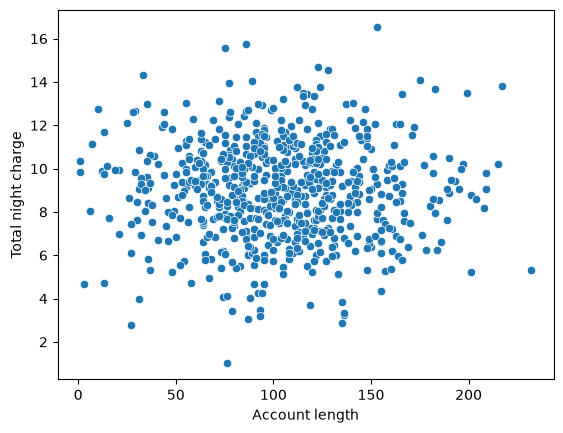

In [74]:
sns.scatterplot(x=df['Account length'],y=df['Total night charge'])

<Axes: xlabel='Account length', ylabel='Total intl minutes'>

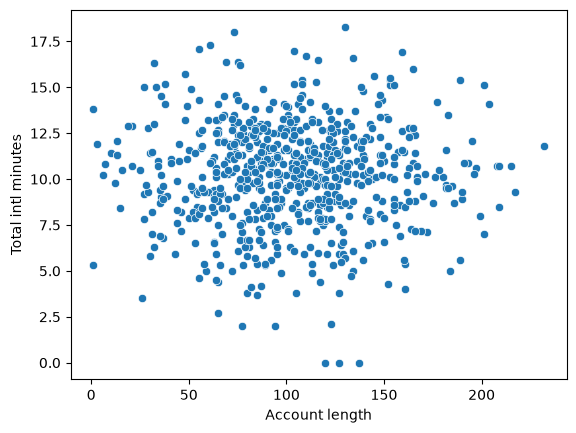

In [75]:
sns.scatterplot(x=df['Account length'],y=df['Total intl minutes'])

<Axes: xlabel='Account length', ylabel='Total intl calls'>

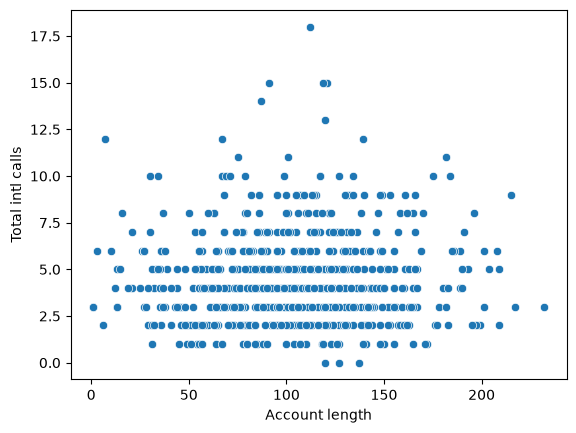

In [76]:
sns.scatterplot(x=df['Account length'],y=df['Total intl calls'])

<Axes: xlabel='Account length', ylabel='Total intl minutes'>

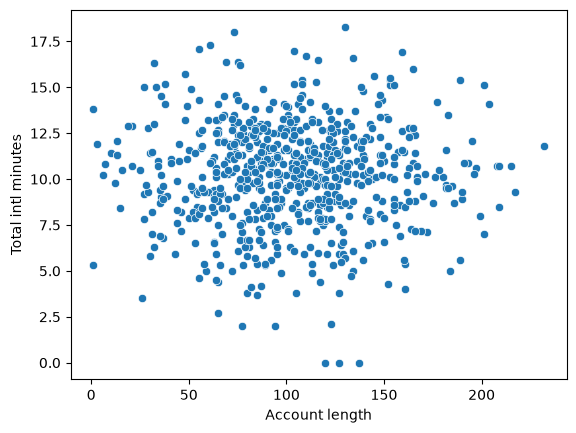

In [77]:
sns.scatterplot(x=df['Account length'],y=df['Total intl minutes'])

<Axes: xlabel='Account length', ylabel='Total intl charge'>

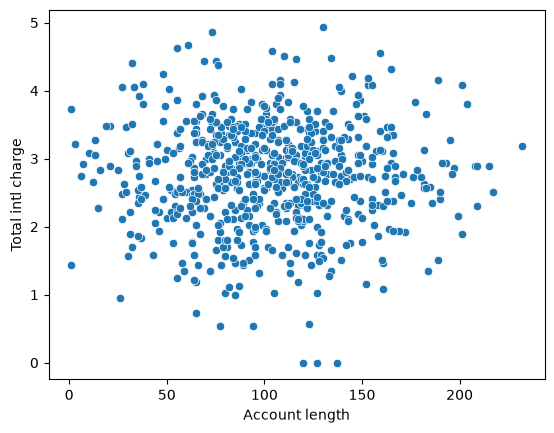

In [78]:
sns.scatterplot(x=df['Account length'],y=df['Total intl charge'])

<Axes: xlabel='Account length', ylabel='Customer service calls'>

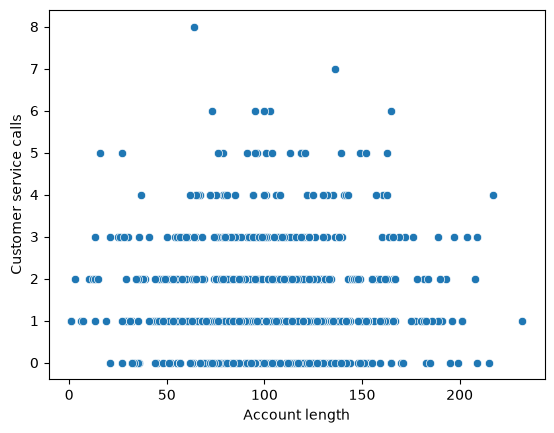

In [79]:
sns.scatterplot(x=df['Account length'],y=df['Customer service calls'])

<Axes: xlabel='International plan', ylabel='Account length'>

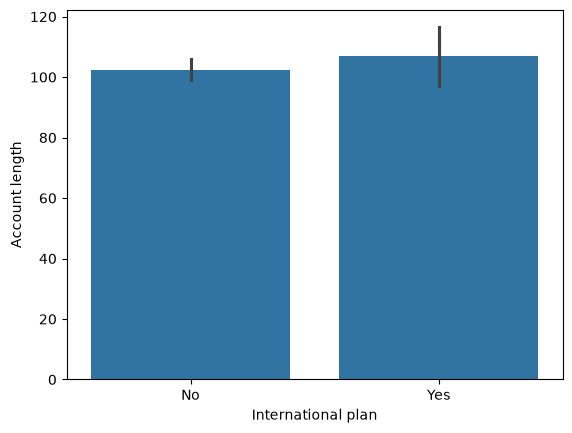

In [80]:
sns.barplot(x=df['International plan'],y=df['Account length'])

<Axes: xlabel='Voice mail plan', ylabel='Account length'>

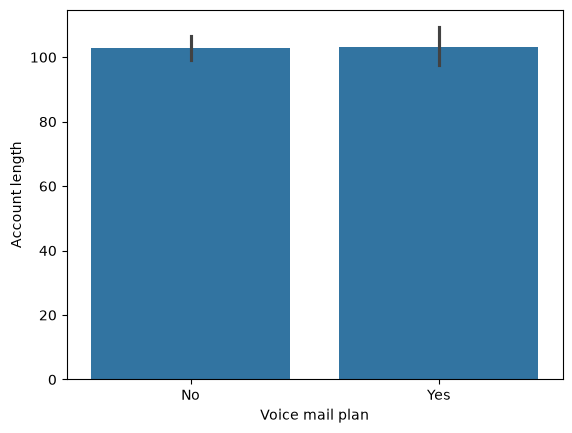

In [81]:
sns.barplot(x=df['Voice mail plan'],y=df['Account length'])

<Axes: xlabel='Churn', ylabel='Account length'>

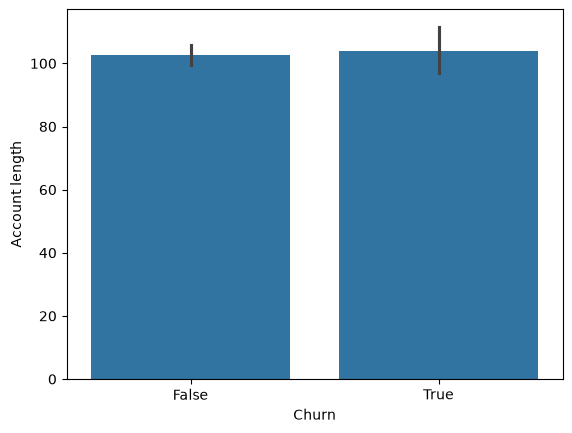

In [82]:
sns.barplot(x=df['Churn'],y=df['Account length'])

<Axes: xlabel='Churn', ylabel='Area code'>

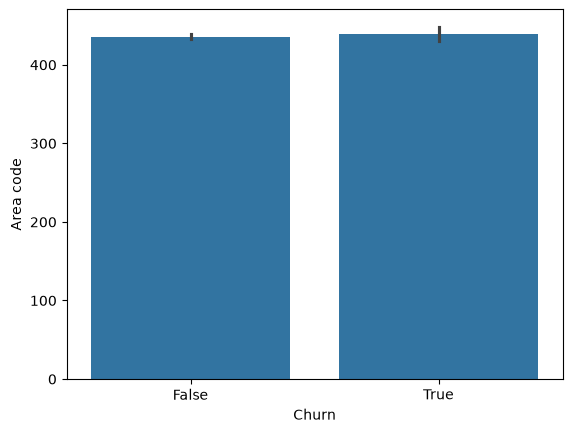

In [83]:
sns.barplot(x=df['Churn'],y=df['Area code'])

<Axes: xlabel='Churn', ylabel='Number vmail messages'>

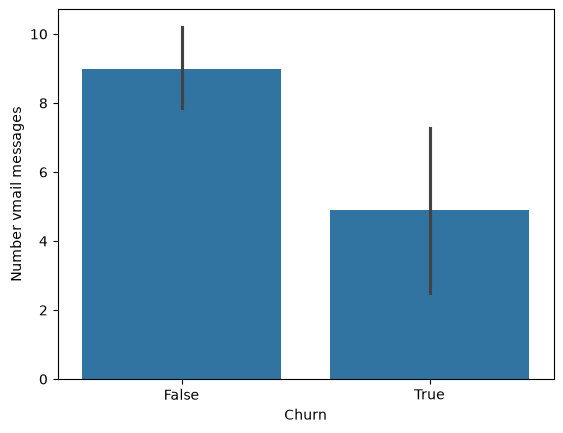

In [84]:
sns.barplot(x=df['Churn'],y=df['Number vmail messages'])

In [85]:
df.columns

Index(['State', 'Account length', 'Area code', 'International plan',
       'Voice mail plan', 'Number vmail messages', 'Total day minutes',
       'Total day calls', 'Total day charge', 'Total eve minutes',
       'Total eve calls', 'Total eve charge', 'Total night minutes',
       'Total night calls', 'Total night charge', 'Total intl minutes',
       'Total intl calls', 'Total intl charge', 'Customer service calls',
       'Churn'],
      dtype='object')

<Axes: xlabel='Churn', ylabel='Total day minutes'>

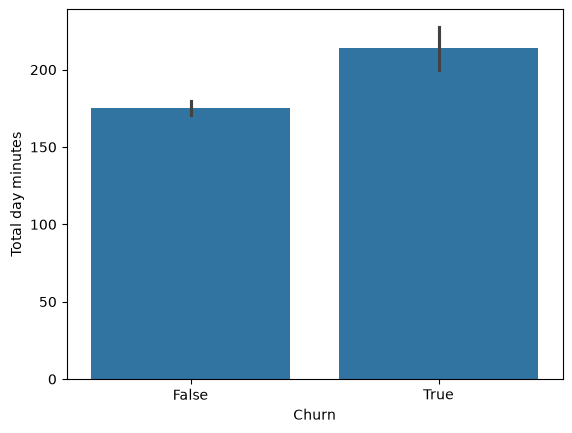

In [86]:
sns.barplot(x=df['Churn'],y=df['Total day minutes'])

<Axes: xlabel='Churn', ylabel='Total day calls'>

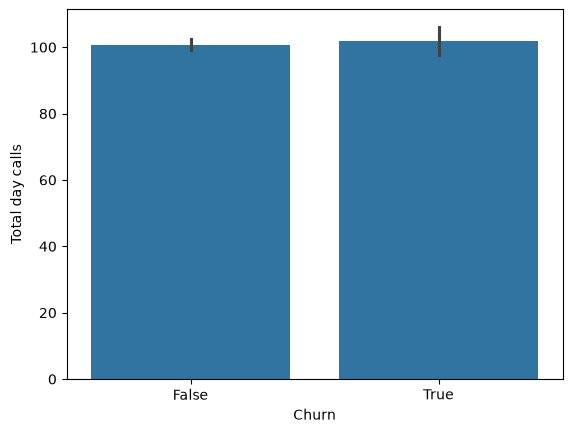

In [87]:
sns.barplot(x=df['Churn'],y=df['Total day calls'])

<Axes: xlabel='Churn', ylabel='Total day charge'>

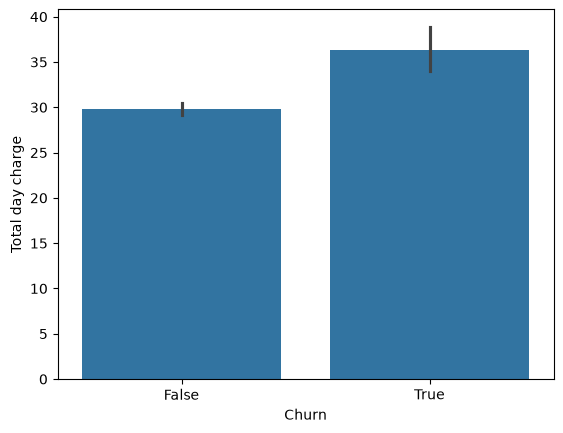

In [88]:
sns.barplot(x=df['Churn'],y=df['Total day charge'])

<Axes: xlabel='Churn', ylabel='Total eve minutes'>

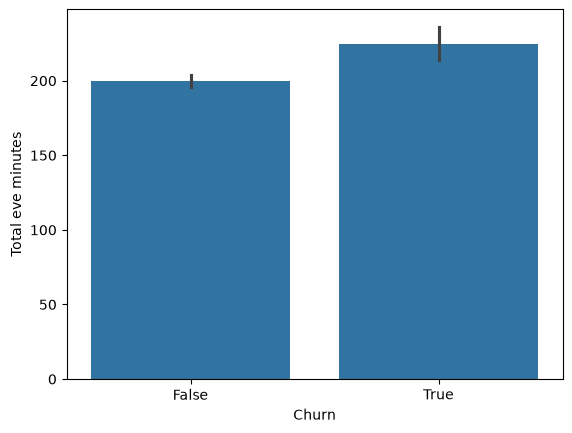

In [89]:
sns.barplot(x=df['Churn'],y=df['Total eve minutes'])

<Axes: xlabel='Churn', ylabel='Total eve calls'>

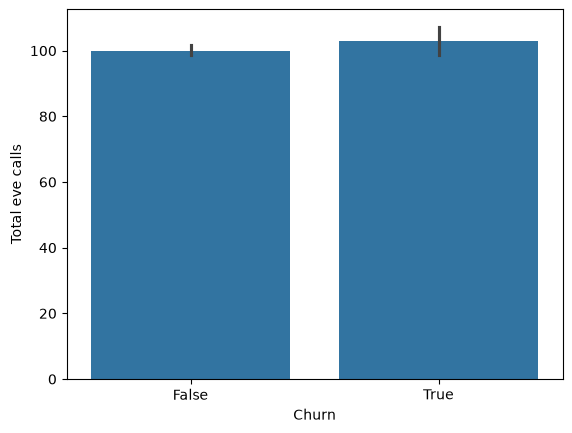

In [90]:
sns.barplot(x=df['Churn'],y=df['Total eve calls'])

<Axes: xlabel='Churn', ylabel='Total eve charge'>

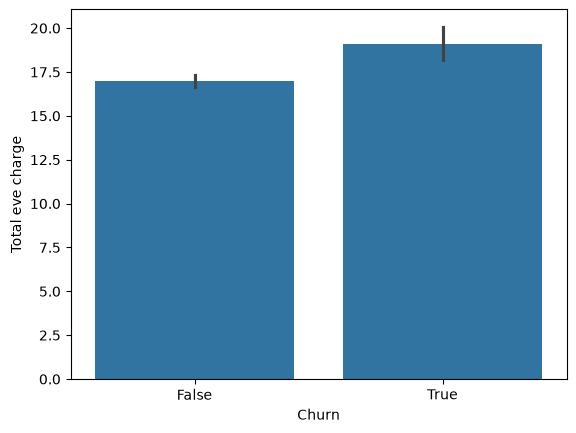

In [91]:
sns.barplot(x=df['Churn'],y=df['Total eve charge'])

<Axes: xlabel='Churn', ylabel='Total night minutes'>

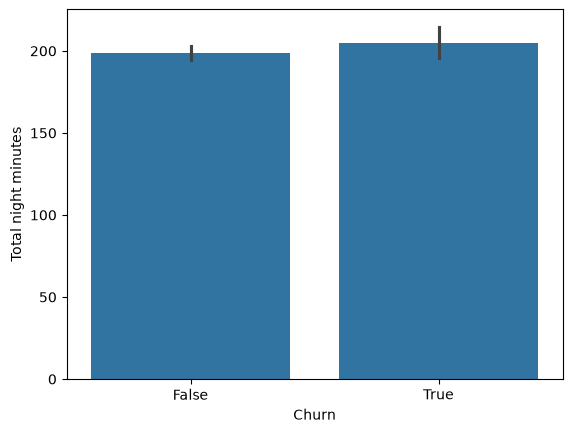

In [92]:
sns.barplot(x=df['Churn'],y=df['Total night minutes'])

<Axes: xlabel='Churn', ylabel='Total night calls'>

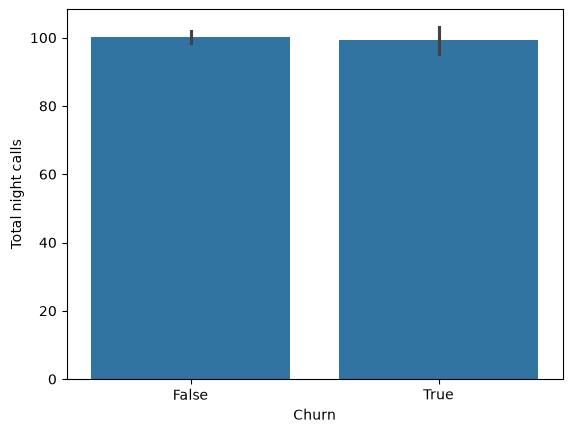

In [93]:
sns.barplot(x=df['Churn'],y=df['Total night calls'])

<Axes: xlabel='Churn', ylabel='Total night charge'>

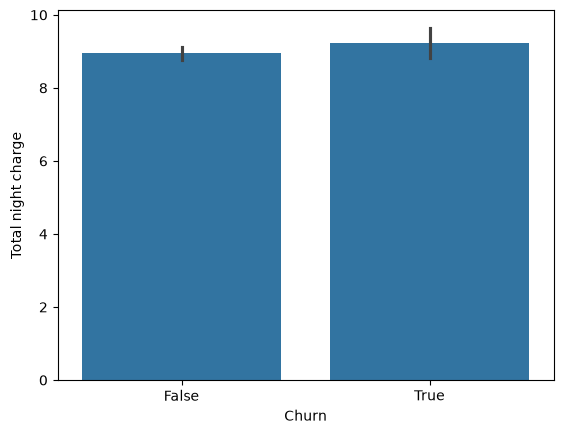

In [94]:
sns.barplot(x=df['Churn'],y=df['Total night charge'])

<Axes: xlabel='Churn', ylabel='Total intl minutes'>

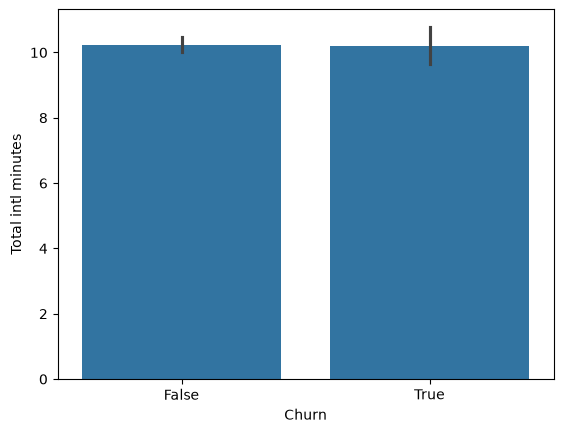

In [95]:
sns.barplot(x=df['Churn'],y=df['Total intl minutes'])

<Axes: xlabel='Churn', ylabel='Total intl calls'>

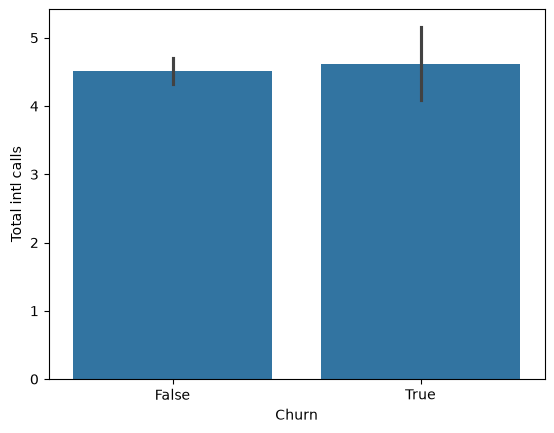

In [96]:
sns.barplot(x=df['Churn'],y=df['Total intl calls'])

<Axes: xlabel='Churn', ylabel='Total intl charge'>

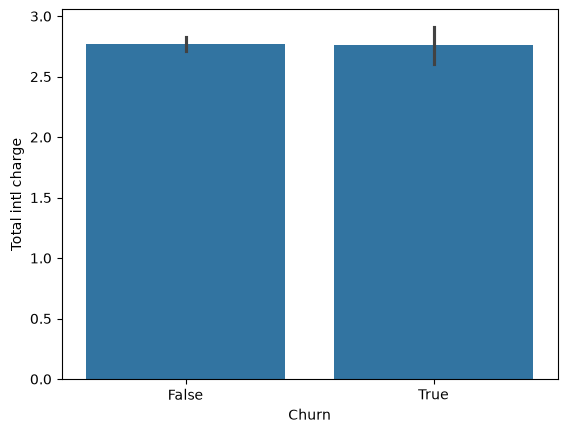

In [97]:
sns.barplot(x=df['Churn'],y=df['Total intl charge'])

<Axes: xlabel='Churn', ylabel='Customer service calls'>

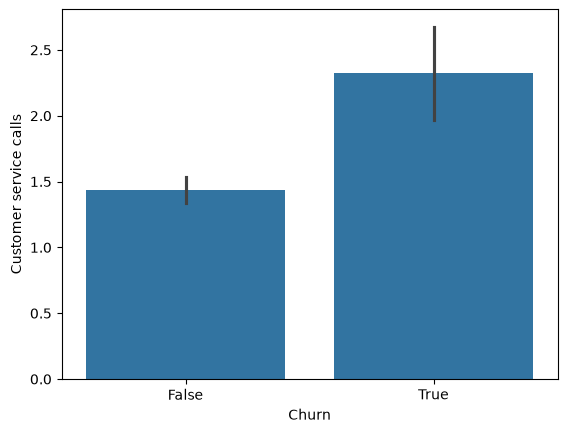

In [98]:
sns.barplot(x=df['Churn'],y=df['Customer service calls'])

In [99]:
label = LabelEncoder()

In [100]:
for column in df.columns:
    if is_numeric_dtype(df[column]):
        continue
    else:
        df[column] = label.fit_transform(df[column])

In [101]:
df.corr()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
State,1.000000,0.047144,0.021339,-0.010796,-0.085049,-0.091541,-0.014128,-0.032697,-0.014126,0.031530,-0.037436,0.031494,0.021822,0.013645,0.021834,0.005987,0.021953,0.006014,-0.001053,0.038488
Account length,0.047144,1.000000,-0.026327,0.029549,0.003918,-0.011993,0.017833,0.035703,0.017839,0.027043,0.021237,0.027051,-0.007527,0.027228,-0.007528,0.002362,0.031279,0.002456,-0.027677,0.012315
Area code,0.021339,-0.026327,1.000000,0.053461,-0.032253,-0.006907,0.051507,-0.008972,0.051492,0.017160,0.017783,0.017182,-0.016832,0.036421,-0.016818,-0.037980,-0.010530,-0.038044,0.000103,0.027129
International plan,-0.010796,0.029549,0.053461,1.000000,0.024382,0.023145,0.050915,0.040889,0.050903,-0.011273,-0.012082,-0.011274,-0.115659,-0.011561,-0.115669,0.013960,0.044762,0.014033,0.025475,0.181634
Voice mail plan,-0.085049,0.003918,-0.032253,0.024382,1.000000,0.956168,-0.060599,-0.025318,-0.060612,0.030493,-0.048341,0.030501,0.026803,0.021533,0.026723,0.048435,-0.022455,0.048504,-0.001355,-0.113465
Number vmail messages,-0.091541,-0.011993,-0.006907,0.023145,0.956168,1.000000,-0.069172,-0.009952,-0.069187,0.040865,-0.051951,0.040876,0.039751,0.003367,0.039680,0.029949,-0.036847,0.029999,0.007859,-0.102381
Total day minutes,-0.014128,0.017833,0.051507,0.050915,-0.060599,-0.069172,1.000000,-0.032306,1.000000,0.017987,0.043219,0.017945,-0.031600,0.052761,-0.031603,-0.006725,0.016597,-0.006841,0.029291,0.242781
Total day calls,-0.032697,0.035703,-0.008972,0.040889,-0.025318,-0.009952,-0.032306,1.000000,-0.032319,-0.004688,0.005851,-0.004664,0.079536,-0.030074,0.079529,-0.015319,-0.005155,-0.015201,-0.045953,0.019360
Total day charge,-0.014126,0.017839,0.051492,0.050903,-0.060612,-0.069187,1.000000,-0.032319,1.000000,0.017983,0.043231,0.017941,-0.031613,0.052748,-0.031616,-0.006720,0.016582,-0.006836,0.029290,0.242777
Total eve minutes,0.031530,0.027043,0.017160,-0.011273,0.030493,0.040865,0.017987,-0.004688,0.017983,1.000000,-0.029077,1.000000,-0.007705,0.001938,-0.007603,-0.027855,0.002929,-0.027887,-0.012213,0.175614


<Axes: >

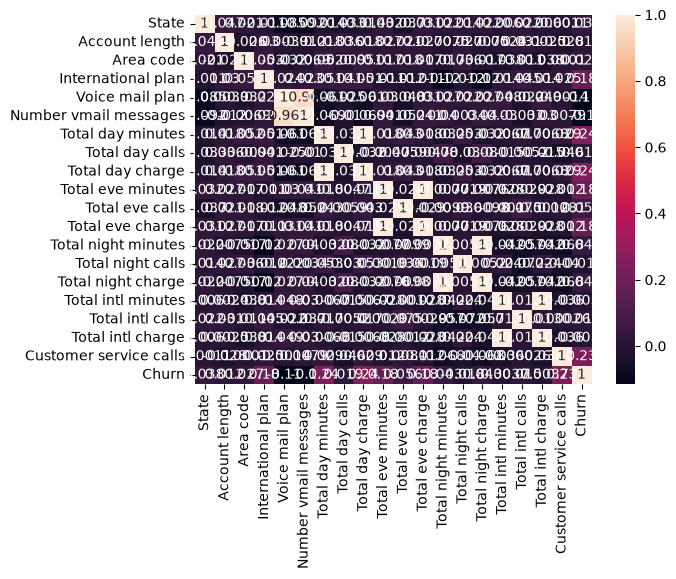

In [102]:
sns.heatmap(df.corr(),annot=True)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6488\107776459.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df)


<Axes: ylabel='Density'>

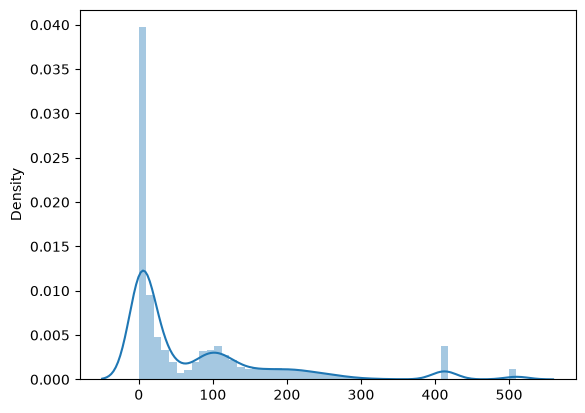

In [103]:
sns.distplot(df)

In [104]:
x=df.drop("Churn",axis=1)
y=df["Churn"]

In [105]:
min_max = MinMaxScaler()
X= min_max.fit_transform(x)
X= pd.DataFrame(X, columns = x.columns)

In [106]:
X.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
0,0.36,0.502165,0.000000,0.0,0.0,0.0,0.514267,0.496296,0.514400,0.967485,0.328244,0.967742,0.559071,0.360902,0.558994,0.475410,0.222222,0.475709,0.125
1,0.30,0.277056,0.068627,0.0,0.0,0.0,0.334630,0.792593,0.334732,0.575072,0.351145,0.575019,0.538752,0.518797,0.539007,0.693989,0.333333,0.694332,0.500
2,0.68,0.692641,0.068627,0.0,0.0,0.0,0.995460,0.274074,0.995422,0.859739,0.458015,0.859715,0.398839,0.646617,0.399097,0.295082,0.500000,0.295547,0.500
3,0.80,0.476190,0.068627,0.0,0.0,0.0,0.273995,0.540741,0.274080,0.284348,0.496183,0.284321,0.483019,0.473684,0.482914,0.420765,0.333333,0.421053,0.250
4,0.22,0.207792,1.000000,0.0,0.0,0.0,0.302853,0.644444,0.302880,0.532356,0.549618,0.532258,0.451379,0.360902,0.451322,0.606557,0.055556,0.607287,0.125


In [107]:
y.head()

0    False
1     True
2     True
3    False
4    False
Name: Churn, dtype: bool

In [108]:
xtrain,xtest,ytrain,ytest =  train_test_split(X,y, train_size=0.70,random_state=23)

In [109]:
model = SVC()

In [116]:
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100, 1000],

    "kernel": ["linear","rbf","poly","sigmoid"],
    "gamma": ["scale","auto",0.001,0.01,0.1,1],
    "degree": [2,3,4,5],
    "coef0": [0.0,0.1,0.5,1.0],
    "class_weight": [None,"balanced"]
}

In [117]:
for key in param_grid:
    print(key)

C
kernel
gamma
degree
coef0
class_weight


In [118]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

In [119]:

    
    grid_search .fit(xtrain,ytrain)
    ypred = grid_search.predict(xtest)
    accuracy = accuracy_score(ytest,ypred)
    

Fitting 10 folds for each of 4608 candidates, totalling 46080 fits


In [122]:

print("Accuracy:",round(accuracy,4))
print("\nClassification Report")
print(classification_report(ytest,ypred,target_names = ["Yes","NO"],zero_division=0 ))

Accuracy: 0.9005

Classification Report
              precision    recall  f1-score   support

         Yes       0.93      0.96      0.94       176
          NO       0.63      0.48      0.55        25

    accuracy                           0.90       201
   macro avg       0.78      0.72      0.74       201
weighted avg       0.89      0.90      0.89       201



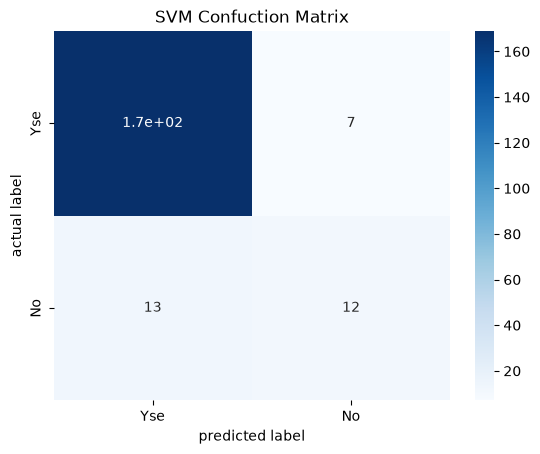

In [123]:
cm = confusion_matrix(ytest, ypred)

sns.heatmap(cm,
           annot=True,
           cmap="Blues" ,
           xticklabels=["Yse","No"],
           yticklabels=["Yse","No"])
plt.xlabel("predicted label")
plt.ylabel("actual label")
plt.title("SVM Confuction Matrix")
plt.show()